# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as seaborn

# Load the cleaned Airbnb dataset from Assignment 6 (or use the backup)
# Make sure your file is uploaded to the Colab files sidebar
df = pd.read_csv('/content/listings (1).csv.gz') # Update filename if using your own cleaned file

# Quick check of the data
print(df.shape)
df.head()

(25715, 90)


/tmp/ipykernel_2582/370343887.py:8: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/listings (1).csv.gz') # Update filename if using your own cleaned file


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1293376226279904342,https://www.airbnb.com/rooms/1293376226279904342,20260916052113,2026-09-18,NaN,555 swanston,good location,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,509664637,...,5.0,5.0,4.0,NaN,NaN,2,0,2,0,0.05
1,1267716269242477675,https://www.airbnb.com/rooms/1267716269242477675,20260916052113,2026-09-18,NaN,On-suite - total privacy,"Relaxing and quite place, easy access to publi...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,473356895,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
2,1167644019888788983,https://www.airbnb.com/rooms/1167644019888788983,20260916052113,2026-09-17,NaN,Entertaining home,Get comfortable and enjoy plenty of extra room...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,22836099,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
3,1686698561880724365,https://www.airbnb.com/rooms/1686698561880724365,20260916052113,2026-09-18,NaN,Welcome home! Nestled in the heart of Melton.,Relax with the whole family at this peaceful p...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,1686691727730752808,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
4,1167133073069986715,https://www.airbnb.com/rooms/1167133073069986715,20260916052113,2026-09-18,NaN,Best fun place with best rates,"Kick back and relax in this calm, stylish space.",NaN,https://a0.muscache.com/pictures/miso/Hosting-...,377597884,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN


## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

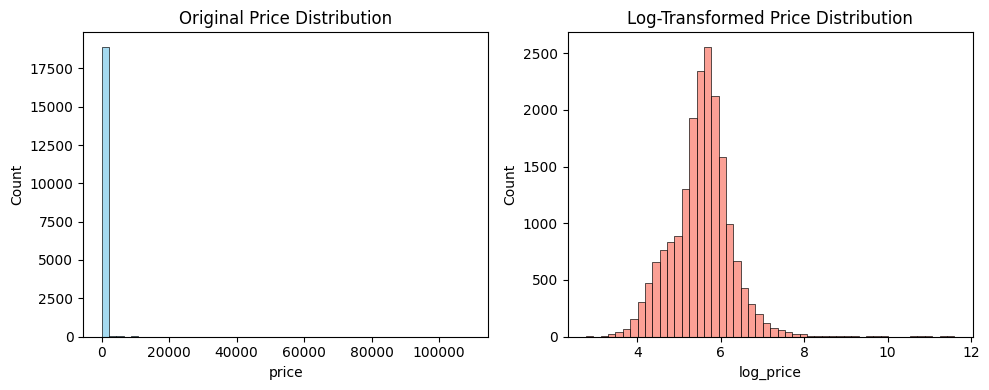

In [26]:
# 1. Plot a histogram of a skewed column (e.g., 'price')
# Note: Ensure price is cleaned/numeric if it includes currency symbols
df['price'] = df['price'].astype(str).str.replace('$', '').str.replace(',', '').astype(float)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
seaborn.histplot(df['price'].dropna(), bins=50, color='skyblue')
plt.title('Original Price Distribution')

# 2. Apply a log transformation to handle skewness
df['log_price'] = np.log1p(df['price'])

# 3. Plot the transformed version
plt.subplot(1, 2, 2)
seaborn.histplot(df['log_price'].dropna(), bins=50, color='salmon')
plt.title('Log-Transformed Price Distribution')
plt.tight_layout()
plt.show()

### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. What column did you examine? I examined the price column because Airbnb pricing data typically has a heavy right skew (a few extremely expensive luxury properties stretch out the scale).

2. What transformation did you try, and why? I applied a logarithmic transformation (np.log1p()) to compress the long tail of high prices and bring the distribution closer to a normal shape.

3. How did the transformed version help make the data more usable for analysis or stakeholder review? The log transformation makes visual interpretation much clearer and prevents extreme outlier properties from disproportionately dominating machine learning models or statistical summaries.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [28]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Drop rows with missing values in target columns for scaling
scaling_df = df.dropna(subset=['price', 'minimum_nights']).copy()

# 1. Min-Max scale 'minimum_nights' (Range 0 to 1)
min_max_scaler = MinMaxScaler()
scaling_df['min_nights_scaled'] = min_max_scaler.fit_transform(scaling_df[['minimum_nights']])

# 2. Z-score scale 'price' (Standardization: mean = 0, std = 1)
standard_scaler = StandardScaler()
scaling_df['price_zscore'] = standard_scaler.fit_transform(scaling_df[['price']])

# Add the new columns back to the main DataFrame
df['min_nights_scaled'] = scaling_df['min_nights_scaled']
df['price_zscore'] = scaling_df['price_zscore']

df[['minimum_nights', 'min_nights_scaled', 'price', 'price_zscore']].head()


,minimum_nights,min_nights_scaled,price,price_zscore
0,1.0,0.0,80.0,-0.167399
1,1.0,0.0,100.0,-0.155410
2,1.0,NaN,NaN,NaN
3,1.0,0.0,56.0,-0.181786
4,1.0,0.0,90.0,-0.161404



### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1. What two columns did you scale, and which methods did you use? I scaled minimum_nights using Min-Max scaling to bound values between 0 and 1, and price using Z-score standardization to center the mean at 0 with a standard deviation of 1.

2. When might these scaled values be more useful than the originals? Scaled values are essential when feeding features into distance-based machine learning algorithms (like K-Means clustering or KNN) or neural networks, ensuring features with larger raw units don't overpower smaller ones.

3. Who at Airbnb might benefit from this transformation and why? Data scientists and pricing algorithm engineers would benefit because normalized features allow multi-variable machine learning models to converge efficiently and fairly weight different listing characteristics.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [29]:
# 1. Check distribution summary of review counts to choose bin edges
print(df['number_of_reviews'].describe())

# 2. Define bins and labels
bins = [-1, 0, 10, 50, df['number_of_reviews'].max()]
labels = ['None', 'Low', 'Medium', 'High']

# 3. Create the new categorical bin column
df['review_volume_category'] = pd.cut(df['number_of_reviews'], bins=bins, labels=labels)

df['review_volume_category'].value_counts()

count    25715.000000
mean        40.529885
std         79.797041
min          0.000000
25%          1.000000
50%         11.000000
75%         43.000000
max       3269.000000
Name: number_of_reviews, dtype: float64


,count
review_volume_category,
Low,8266
Medium,7126
High,5738
None,4585


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. What column did you group, and how many categories did you use? I grouped the number_of_reviews column into 4 categories: "None", "Low", "Medium", and "High".

2. Why might someone prefer this grouped view over raw numbers? Grouping turns continuous, noisy counts into intuitive business tiers, making it easier to quickly segment properties without getting bogged down in exact numerical differences.

3. Who would this help at Airbnb, and how? The marketing team and host success managers would benefit because they can easily identify unreviewed listings needing attention ("None") versus top-performing, highly-reviewed properties ("High") to design targeted campaigns or tier rewards.


## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [30]:
# 1. Ratio/Interaction: Price per accommodate (cost efficiency metric)
# Handle potential division by zero
df['price_per_accommodate'] = df['price'] / df['accommodates'].replace(0, np.nan)

# 2. Condition Flag: Long-term stay friendly (minimum nights >= 30)
df['is_long_term_only'] = (df['minimum_nights'] >= 30).astype(int)

df[['price', 'accommodates', 'price_per_accommodate', 'minimum_nights', 'is_long_term_only']].head()

,price,accommodates,price_per_accommodate,minimum_nights,is_long_term_only
0,80.0,2,40.0,1.0,0
1,100.0,2,50.0,1.0,0
2,NaN,2,NaN,1.0,0
3,56.0,2,28.0,1.0,0
4,90.0,2,45.0,1.0,0


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. What two new columns did you create and why? I created price_per_accommodate to measure cost efficiency per guest slot, and is_long_term_only as a binary flag to isolate properties catering to monthly or corporate travelers.

2. Who would use them (e.g., host, manager, or platform)? Guests and travel planners would use the price-per-person metric to evaluate value, while platform managers and long-term housing analysts would use the long-term stay flag.

3. How could they help someone make a better decision? Guests can easily compare true value across listings of varying sizes, and city planners can track how many properties operate as traditional long-term rentals versus short-term vacation rentals.

## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [31]:
# Choose 'room_type' for one-hot encoding
# Check unique values first
print(df['room_type'].unique())

# Apply one-hot encoding
df = pd.get_dummies(df, columns=['room_type'], prefix='room', drop_first=True)

df.head()

['Private room' 'Entire home/apt' 'Shared room' 'Hotel room']


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,reviews_per_month,log_price,min_nights_scaled,price_zscore,review_volume_category,price_per_accommodate,is_long_term_only,room_Hotel room,room_Private room,room_Shared room
0,1293376226279904342,https://www.airbnb.com/rooms/1293376226279904342,20260916052113,2026-09-18,NaN,555 swanston,good location,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,509664637,...,0.05,4.394449,0.0,-0.167399,Low,40.0,0,False,True,False
1,1267716269242477675,https://www.airbnb.com/rooms/1267716269242477675,20260916052113,2026-09-18,NaN,On-suite - total privacy,"Relaxing and quite place, easy access to publi...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,473356895,...,NaN,4.615121,0.0,-0.155410,None,50.0,0,False,True,False
2,1167644019888788983,https://www.airbnb.com/rooms/1167644019888788983,20260916052113,2026-09-17,NaN,Entertaining home,Get comfortable and enjoy plenty of extra room...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,22836099,...,NaN,NaN,NaN,NaN,None,NaN,0,False,True,False
3,1686698561880724365,https://www.airbnb.com/rooms/1686698561880724365,20260916052113,2026-09-18,NaN,Welcome home! Nestled in the heart of Melton.,Relax with the whole family at this peaceful p...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,1686691727730752808,...,NaN,4.043051,0.0,-0.181786,None,28.0,0,False,True,False
4,1167133073069986715,https://www.airbnb.com/rooms/1167133073069986715,20260916052113,2026-09-18,NaN,Best fun place with best rates,"Kick back and relax in this calm, stylish space.",NaN,https://a0.muscache.com/pictures/miso/Hosting-...,377597884,...,NaN,4.510860,0.0,-0.161404,None,45.0,0,False,True,False


### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1. What column did you encode and why? I encoded the room_type column because machine learning models and regression algorithms require numeric input rather than text strings.

2. What encoding method did you use? I used One-Hot Encoding (pd.get_dummies), which creates binary indicator columns for each category since room types are nominal (unordered).

3. How could this transformation help a pricing model, dashboard, or business report? It enables predictive pricing models to quantitatively measure how much a specific listing type (like an entire home vs. a private room) impacts nightly rates.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [32]:
# Export the transformed dataset to CSV
output_filename = 'cleaned_airbnb_data_7.csv'
df.to_csv(output_filename, index=False)

print(f"Dataset successfully exported to {output_filename}")

Dataset successfully exported to cleaned_airbnb_data_7.csv


## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. What transformation step felt most important or interesting? Creating custom business variables (price_per_accommodate and is_long_term_only) was the most impactful because it translated raw administrative data into actionable consumer insights.

2. Which of your changes would be most useful to a host, analyst, or city planner? The review volume grouping and long-term stay flags are exceptionally useful for city planners monitoring housing availability and hosts benchmarking their competitive positioning.

3. If you were going to build a tool or dashboard, what would you do next with this data? I would build an interactive Streamlit or Tableau dashboard featuring geographical heatmaps of scaled prices and filterable guest segmentation tiers.

4. How does this relate to your customized learning outcome you created in canvas? This assignment directly reinforces data engineering capabilities by demonstrating how raw data extraction flows seamlessly into structured feature preparation for predictive modeling.



## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [24]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_07_data_transformation.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_y